In [1]:
from astropy import units
from astropy.time import Time
from astropy.visualization import quantity_support

from matplotlib import pyplot

import numpy 

from src.selflensing.fitting import self_lensing_system_from_fit
from src.selflensing.generators import LightcurveGenerator, RVGenerator, GPLightcurveGenerator
from src.selflensing.models import SelfLensingSystem

from src.selflensing.gp import TESSGP

In [2]:
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x11b406e40>

In [3]:
LENSING_METHOD = 'IntegratedWittMao'

In [4]:
sls = SelfLensingSystem(
    a=5 * units.AU,
    i=(0.5*numpy.pi - 0.0001) * units.rad,
    Macc=10*units.M_sun,
    Mcomp=0.1 * units.M_sun,
    e=0 * units.dimensionless_unscaled,
    d=0.1*units.kpc,
)
sls.Rcomp, sls.Tmag, sls.Teff, sls.porb, sls.tau_eff, sls.b, sls.b_max, sls.rE(), sls.i

(Quantity(Array(0.15848932, dtype=float64), unit='solRad'),
 Array(20.16698893, dtype=float64),
 Quantity(Array(1933.42166345, dtype=float64), unit='K'),
 Quantity(Array(1284.96928449, dtype=float64), unit='d'),
 Quantity(Array(0.17039001, dtype=float64), unit='d'),
 Quantity(Array(0.35586281, dtype=float64), unit=''),
 Quantity(Array(1.52457693, dtype=float64), unit=''),
 Quantity(Array(2.10190371e+08, dtype=float64), unit='m'),
 Quantity(Array(1.57069633, dtype=float64), unit='rad'))

In [5]:
# peak_time = Time("2025-01-03")
# start_time = peak_time - sls.tau_eff / 2
# end_time = peak_time + sls.tau_eff / 2
start_time = Time("2025-01-01")
end_time = Time("2025-01-27")

# start_time, peak_time, end_time

In [6]:
lcg = GPLightcurveGenerator(sls, start_time=start_time, end_time=end_time, ev=True, db=True, sl=False, lensing_method=LENSING_METHOD, bins=27*24*6, gp=TESSGP, kernel_type='F')
rvg = RVGenerator(lensing_system=sls, start_time=start_time, end_time=end_time, peak_time=lcg.peak_time)

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}


In [7]:
# pyplot.scatter(lcg.times.jd, lcg.flux_array, s=2, alpha=0.5, c='blue')
# pyplot.plot(lcg.times.jd, lcg.flux_array - lcg.gp.generate(), c='red')

In [8]:
# model_sls = SelfLensingSystem(
#     a=5 * units.AU,
#     i=0.45*numpy.pi * units.rad,
#     Macc=10*units.M_sun,
#     Mcomp=5 * units.M_sun,
#     e=0 * units.dimensionless_unscaled,
#     d=10*units.kpc,
# )
# plain_lcg = LightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6)
# model_plain_lcg = LightcurveGenerator(model_sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6)

In [9]:
# model_lcg = GPLightcurveGenerator(model_sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6, gp=TESSGP)
# model_lcg.gp.condition(lcg.flux_array)

In [10]:
# model_lcg = GPLightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, bins=27*24*6, gp=TESSGP)
# model_lcg.gp.condition(lcg.flux_array)

comps: {'F': JitTracer<float64[2]>}
Quantity['length'](5., unit='AU') Quantity['mass'](10., unit='solMass') Quantity['mass'](0.1, unit='solMass') Quantity['dimensionless'](0., unit='') Quantity['dimensionless'](0.35586281, unit='') Quantity['angle'](1.57069633, unit='rad')


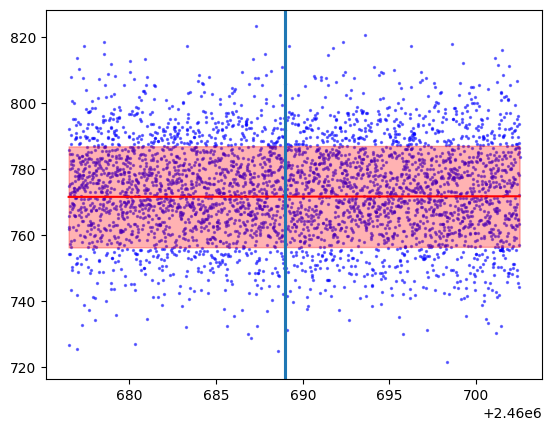

(Array([771.44578015, 771.44582795, 771.44587575, ..., 771.63168997,
        771.63173775, 771.63178553], dtype=float64),
 array([15.30753597, 15.30753597, 15.30753597, ..., 15.30753597,
        15.30753597, 15.30753597], shape=(3888,)))

In [11]:
# scale_factor = numpy.mean(lcg.gp.generate())
pyplot.scatter(lcg.times.jd, lcg.flux_array  , s=2, alpha=0.5, c='blue')
# pyplot.plot(plain_lcg.times.jd, plain_lcg.flux_array, c='green')
# model_gp_f = model_lcg.gp.generate()
# pyplot.scatter(model_lcg.times.jd,( 1+(lcg.flux_array - model_gp_f)/numpy.mean(model_gp_f)), c='red', s=2, alpha=0.5,)
mu = lcg.gp.model.loc
std = numpy.sqrt(lcg.gp.model.variance)
pyplot.plot(lcg.times.jd, mu , c='red')
pyplot.fill_between(lcg.times.jd, mu + std, mu - std, color="red", alpha=0.3)
pyplot.axvline(lcg.peak_time.jd + sls.tau_sl.to(units.day).value / 2)
pyplot.axvline(lcg.peak_time.jd - sls.tau_sl.to(units.day).value / 2)
# pyplot.plot(model_plain_lcg.times.jd, model_plain_lcg.flux_array, c='orange')
# pyplot.xlim((peak_time.jd - sls.tau_eff.value/2, peak_time.jd + sls.tau_eff.value/2))
print(lcg.lensing_system.a, lcg.lensing_system.Macc, lcg.lensing_system.Mcomp, lcg.lensing_system.e, lcg.lensing_system.b, lcg.lensing_system.i)
pyplot.show()
mu, std

In [12]:
lcg.meta

{'a': 5.0,
 'i': 1.5706963267948966,
 'Mbh': 10.0,
 'Rstar': 0.15848931924611134,
 'Mstar': 0.1,
 'Teff': 1933.421663448605,
 'e': 0.0,
 'peri': 0.0,
 'd': 0.1,
 'P': 1284.9692844940676,
 'b': 0.3558628059497426,
 'tau_eff': 0.17039001158317096,
 'tau_sl': 0.04695425299761033,
 'peak_t': np.float64(2460688.981605351),
 'amp_el': -4.334171228925444e-10,
 'amp_db': 0.00012534274194474928,
 'mean_cv': 0.019840267636181203}

In [13]:
lcg.times.jd

array([2460676.5       , 2460676.50668896, 2460676.51337793, ...,
       2460702.48662207, 2460702.49331104, 2460702.5       ],
      shape=(3888,))

In [14]:
t = lcg.timeseries
t.write('lc.fits.gz', overwrite=True)

In [15]:
t['time']

<Time object: scale='utc' format='iso' value=['2025-01-01 00:00:00.000' '2025-01-01 00:09:37.926'
 '2025-01-01 00:19:15.853' ... '2025-01-26 23:40:44.147'
 '2025-01-26 23:50:22.074' '2025-01-27 00:00:00.000']>

In [16]:
from astropy.table import Table
from astropy.timeseries import TimeSeries

t = TimeSeries.read('lc.fits.gz', astropy_native=True)
t

time,flux,flux_err
,,
Time,float64,float64
2460676.5,773.0327672484932,nan
2460676.506688963,797.5411597515192,nan
2460676.5133779263,806.63494015556,nan
2460676.5200668895,781.415873738072,nan
2460676.5267558526,796.4743952431395,nan
2460676.5334448162,786.8920140858404,nan
2460676.5401337794,780.9926154133279,nan
2460676.5468227426,770.5443689117101,nan


In [17]:
# import pandas

# greg_sample = pandas.read_pickle('/Users/adam/Code/greg/SW_std_sldata_bhs.pkl.gz').sample(10000)[["Macc", "Mcomp", "a"]]
# # 

In [18]:
# greg_sample['a'] = (greg_sample['a'].to_numpy() * units.R_sun).to(units.AU).value
# greg_sample

In [19]:
# greg_sample['a'].plot(kind='hist', logx=True, bins=10000)
# min(greg_sample['a'])

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](3.08548286, unit='AU') 
Porb= Quantity['time'](384.23888563, unit='d') 
Macc= Quantity['mass'](8.0910925, unit='solMass') 
Mcomp= Quantity['mass'](18.45274082, unit='solMass') 
e= Quantity['dimensionless'](0.08760143, unit='') 
b= Quantity['dimensionless'](0.20449533, unit='')


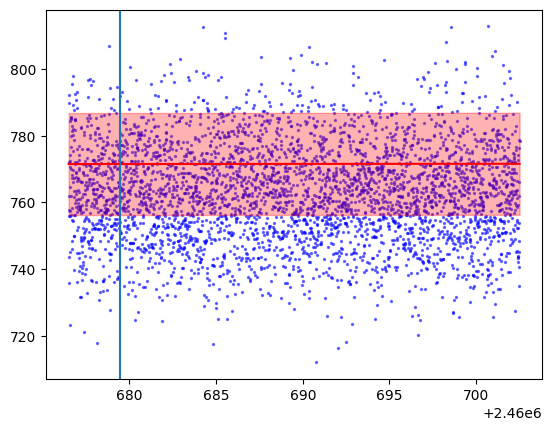

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](30.59350612, unit='AU') 
Porb= Quantity['time'](8320.23878877, unit='d') 
Macc= Quantity['mass'](21.61577565, unit='solMass') 
Mcomp= Quantity['mass'](33.56820527, unit='solMass') 
e= Quantity['dimensionless'](0.6232151, unit='') 
b= Quantity['dimensionless'](0.12045124, unit='')


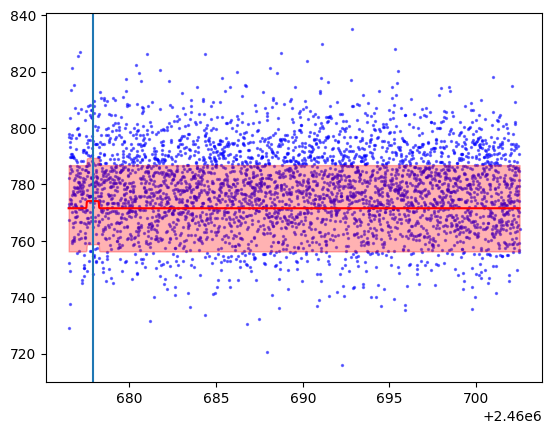

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](116.11473591, unit='AU') 
Porb= Quantity['time'](61611.39976017, unit='d') 
Macc= Quantity['mass'](37.54775437, unit='solMass') 
Mcomp= Quantity['mass'](17.47428948, unit='solMass') 
e= Quantity['dimensionless'](0.7656915, unit='') 
b= Quantity['dimensionless'](0.54159751, unit='')


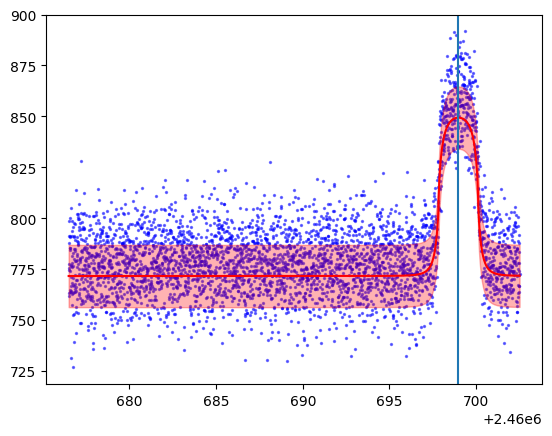

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](106.28224519, unit='AU') 
Porb= Quantity['time'](73386.58731777, unit='d') 
Macc= Quantity['mass'](6.35511888, unit='solMass') 
Mcomp= Quantity['mass'](23.38520064, unit='solMass') 
e= Quantity['dimensionless'](0.61241487, unit='') 
b= Quantity['dimensionless'](0.28510819, unit='')


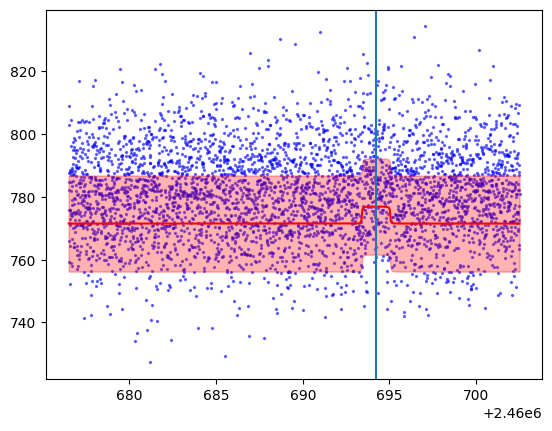

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](0.45760814, unit='AU') 
Porb= Quantity['time'](12.39563363, unit='d') 
Macc= Quantity['mass'](49.99530004, unit='solMass') 
Mcomp= Quantity['mass'](33.20801373, unit='solMass') 
e= Quantity['dimensionless'](0.45838505, unit='') 
b= Quantity['dimensionless'](0.00038857, unit='')


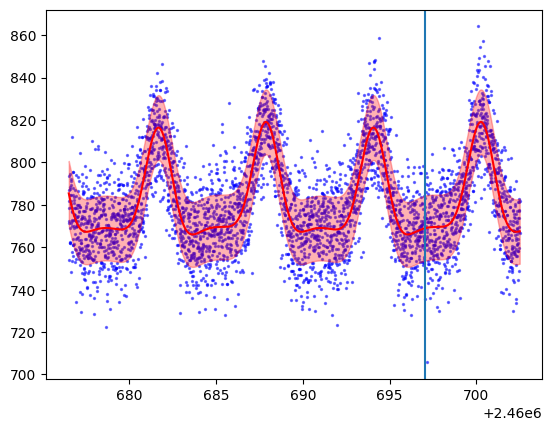

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](0.39703341, unit='AU') 
Porb= Quantity['time'](12.39233183, unit='d') 
Macc= Quantity['mass'](44.55295309, unit='solMass') 
Mcomp= Quantity['mass'](9.81862618, unit='solMass') 
e= Quantity['dimensionless'](0.26528068, unit='') 
b= Quantity['dimensionless'](0.01695144, unit='')


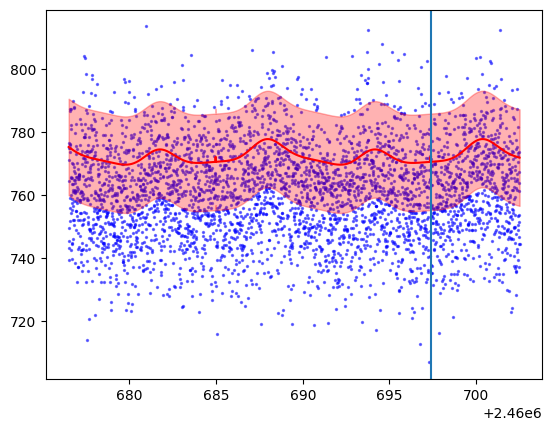

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](50.23255645, unit='AU') 
Porb= Quantity['time'](15869.03357217, unit='d') 
Macc= Quantity['mass'](35.30463149, unit='solMass') 
Mcomp= Quantity['mass'](31.84625323, unit='solMass') 
e= Quantity['dimensionless'](0.06770576, unit='') 
b= Quantity['dimensionless'](0.09596051, unit='')


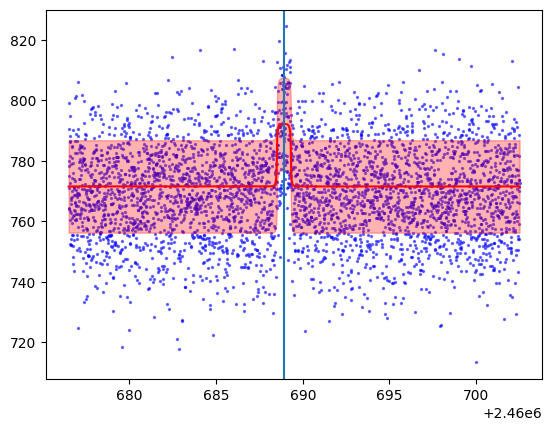

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](1.61218873, unit='AU') 
Porb= Quantity['time'](95.02678462, unit='d') 
Macc= Quantity['mass'](12.10180139, unit='solMass') 
Mcomp= Quantity['mass'](49.80700488, unit='solMass') 
e= Quantity['dimensionless'](0.15420936, unit='') 
b= Quantity['dimensionless'](0.14901694, unit='')


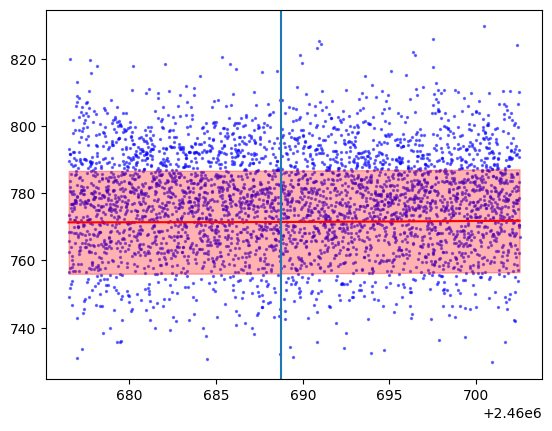

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](6.11074465, unit='AU') 
Porb= Quantity['time'](1042.01862296, unit='d') 
Macc= Quantity['mass'](9.92872001, unit='solMass') 
Mcomp= Quantity['mass'](18.10807084, unit='solMass') 
e= Quantity['dimensionless'](0.19265704, unit='') 
b= Quantity['dimensionless'](0.21639487, unit='')


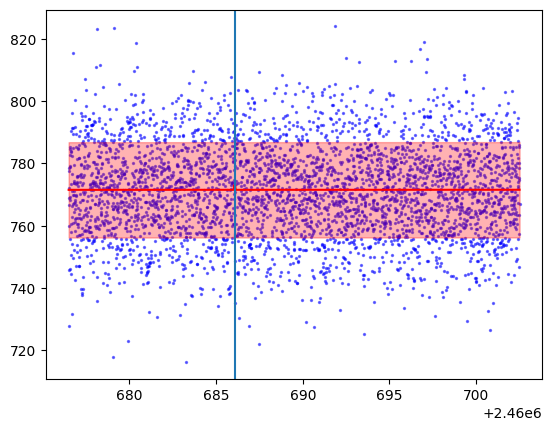

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](9.35641393, unit='AU') 
Porb= Quantity['time'](1255.53557662, unit='d') 
Macc= Quantity['mass'](29.3199599, unit='solMass') 
Mcomp= Quantity['mass'](40.00140215, unit='solMass') 
e= Quantity['dimensionless'](0.43117498, unit='') 
b= Quantity['dimensionless'](0.23439538, unit='')


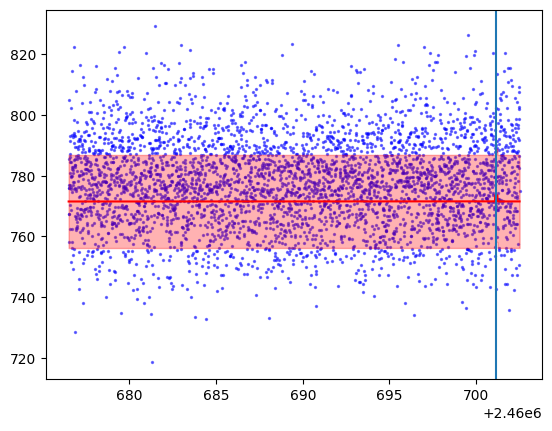

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](146.00909334, unit='AU') 
Porb= Quantity['time'](85097.80271356, unit='d') 
Macc= Quantity['mass'](14.5122529, unit='solMass') 
Mcomp= Quantity['mass'](42.83331705, unit='solMass') 
e= Quantity['dimensionless'](0.00776471, unit='') 
b= Quantity['dimensionless'](1.56906694, unit='')


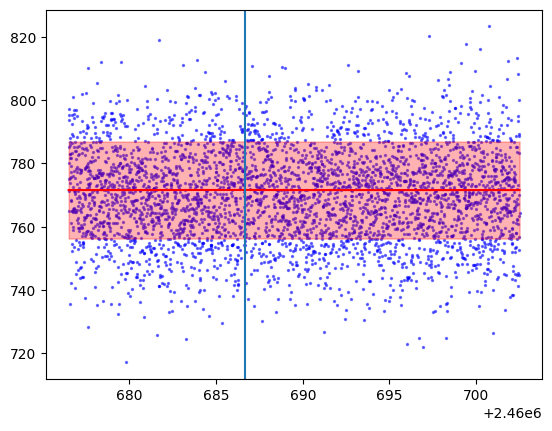

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](0.23436539, unit='AU') 
Porb= Quantity['time'](5.75016527, unit='d') 
Macc= Quantity['mass'](4.61064666, unit='solMass') 
Mcomp= Quantity['mass'](47.33111196, unit='solMass') 
e= Quantity['dimensionless'](0.18970169, unit='') 
b= Quantity['dimensionless'](0.07543439, unit='')


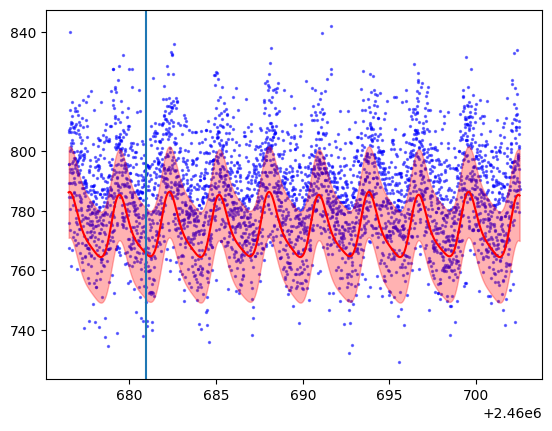

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](6.18184222, unit='AU') 
Porb= Quantity['time'](907.77195552, unit='d') 
Macc= Quantity['mass'](33.9382719, unit='solMass') 
Mcomp= Quantity['mass'](4.30870201, unit='solMass') 
e= Quantity['dimensionless'](0.36043249, unit='') 
b= Quantity['dimensionless'](0.02467534, unit='')


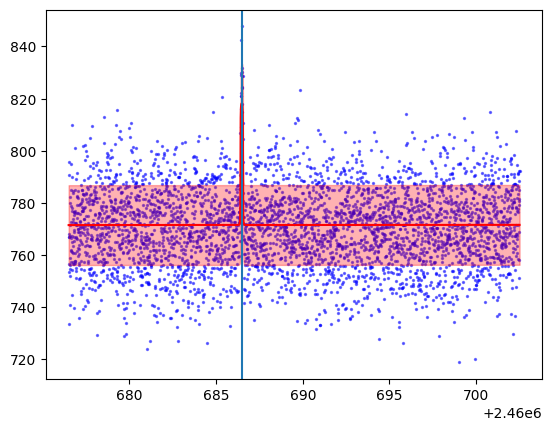

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](0.35766655, unit='AU') 
Porb= Quantity['time'](11.94979732, unit='d') 
Macc= Quantity['mass'](18.55316301, unit='solMass') 
Mcomp= Quantity['mass'](24.19433945, unit='solMass') 
e= Quantity['dimensionless'](0.16318672, unit='') 
b= Quantity['dimensionless'](0.05989122, unit='')


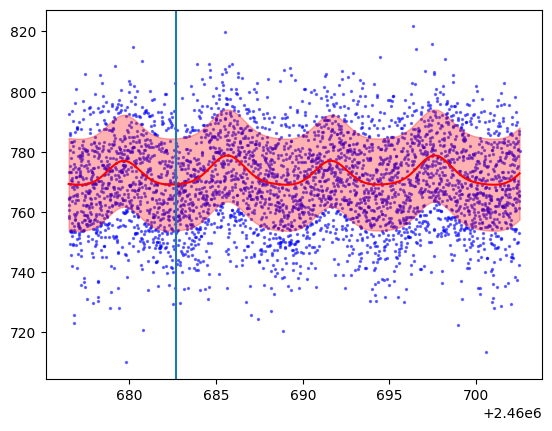

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](163.10907888, unit='AU') 
Porb= Quantity['time'](117208.04690652, unit='d') 
Macc= Quantity['mass'](35.58555344, unit='solMass') 
Mcomp= Quantity['mass'](6.55656866, unit='solMass') 
e= Quantity['dimensionless'](0.00522636, unit='') 
b= Quantity['dimensionless'](0.94659059, unit='')


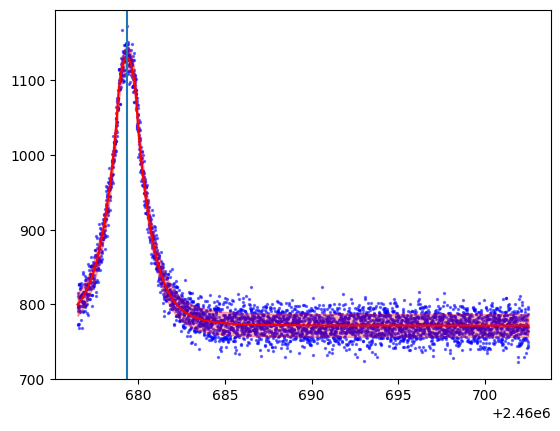

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](2.32220918, unit='AU') 
Porb= Quantity['time'](141.18414079, unit='d') 
Macc= Quantity['mass'](46.4472849, unit='solMass') 
Mcomp= Quantity['mass'](37.36912158, unit='solMass') 
e= Quantity['dimensionless'](0.57160191, unit='') 
b= Quantity['dimensionless'](0.15313373, unit='')


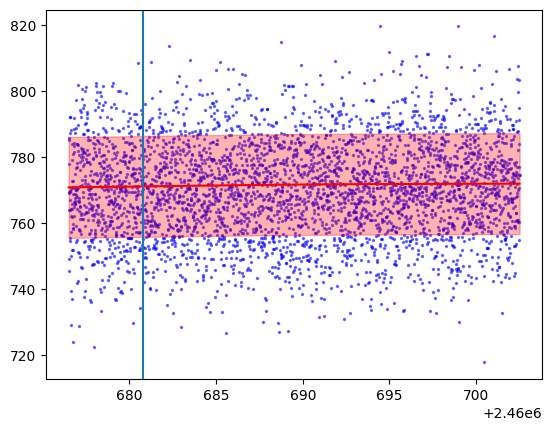

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](12.89800054, unit='AU') 
Porb= Quantity['time'](1762.4030831, unit='d') 
Macc= Quantity['mass'](45.20218061, unit='solMass') 
Mcomp= Quantity['mass'](46.96016896, unit='solMass') 
e= Quantity['dimensionless'](0.47315004, unit='') 
b= Quantity['dimensionless'](0.26891247, unit='')


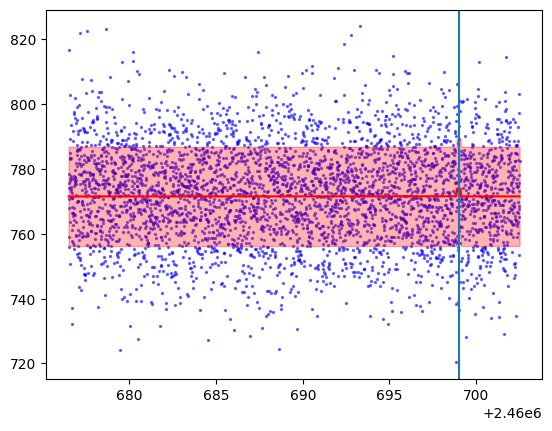

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](0.49962966, unit='AU') 
Porb= Quantity['time'](21.27221916, unit='d') 
Macc= Quantity['mass'](1.60994891, unit='solMass') 
Mcomp= Quantity['mass'](35.1619371, unit='solMass') 
e= Quantity['dimensionless'](0.29520742, unit='') 
b= Quantity['dimensionless'](0.00396044, unit='')


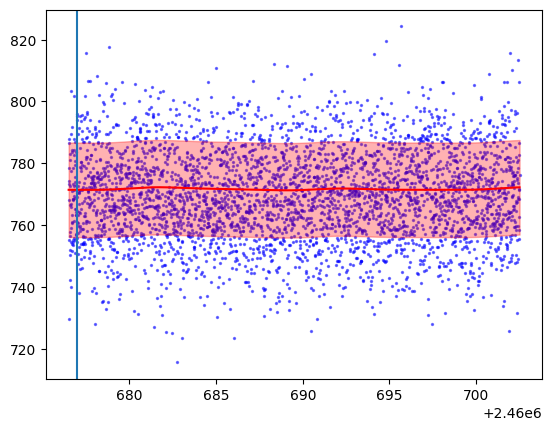

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](42.03382938, unit='AU') 
Porb= Quantity['time'](21157.16259232, unit='d') 
Macc= Quantity['mass'](4.61980212, unit='solMass') 
Mcomp= Quantity['mass'](17.51516483, unit='solMass') 
e= Quantity['dimensionless'](0.90748239, unit='') 
b= Quantity['dimensionless'](4.60636544, unit='')


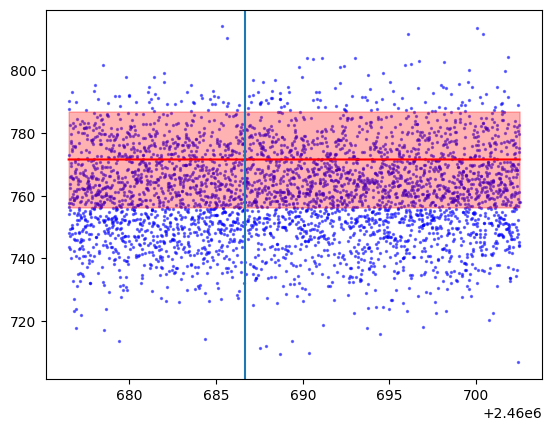

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](4.24621268, unit='AU') 
Porb= Quantity['time'](455.44571011, unit='d') 
Macc= Quantity['mass'](31.14952035, unit='solMass') 
Mcomp= Quantity['mass'](18.09170481, unit='solMass') 
e= Quantity['dimensionless'](0.10543746, unit='') 
b= Quantity['dimensionless'](0.01561149, unit='')


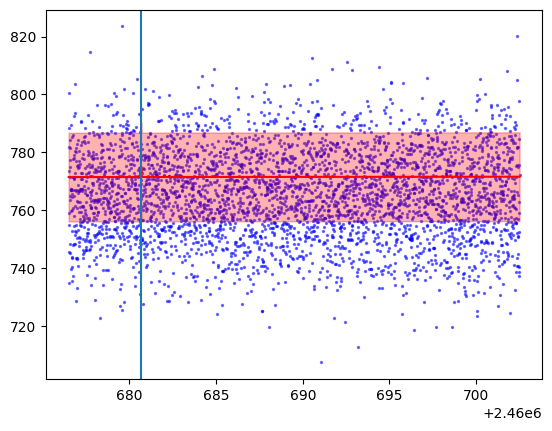

comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
comps: {'F': JitTracer<float64[2]>}
a= Quantity['length'](86.80586221, unit='AU') 
Porb= Quantity['time'](32521.11448247, unit='d') 
Macc= Quantity['mass'](47.7346584, unit='solMass') 
Mcomp= Quantity['mass'](34.77659394, unit='solMass') 
e= Quantity['dimensionless'](0.39434672, unit='') 
b= Quantity['dimensionless'](0.13275174, unit='')


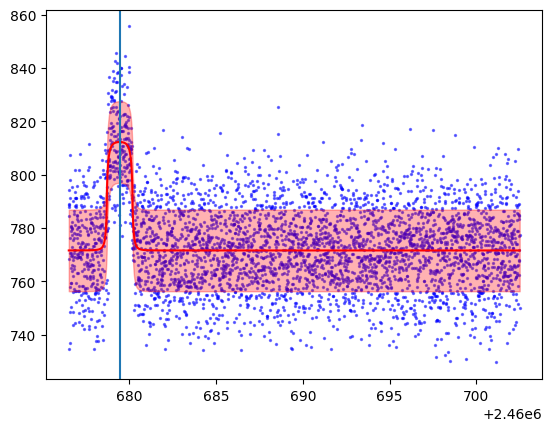

In [ ]:
for lcg in GPLightcurveGenerator.factory(lcg.gp, total=100, start_time=start_time, end_time=end_time, bins=27*24*6, kernel_type='F'):
    # scale_factor = numpy.mean(lcg.gp.generate())
    pyplot.scatter(lcg.times.jd, lcg.flux_array  , s=2, alpha=0.5, c='blue')
    # pyplot.plot(plain_lcg.times.jd, plain_lcg.flux_array, c='green')
    # model_gp_f = model_lcg.gp.generate()
    # pyplot.scatter(model_lcg.times.jd,( 1+(lcg.flux_array - model_gp_f)/numpy.mean(model_gp_f)), c='red', s=2, alpha=0.5,)
    mu = lcg.gp.model.loc
    std = numpy.sqrt(lcg.gp.model.variance)
    pyplot.plot(lcg.times.jd, mu , c='red')
    pyplot.fill_between(lcg.times.jd, mu + std, mu - std, color="red", alpha=0.3)
    # pyplot.plot(model_plain_lcg.times.jd, model_plain_lcg.flux_array, c='orange')
    # pyplot.xlim((peak_time.jd - sls.tau_eff.value/2, peak_time.jd + sls.tau_eff.value/2))
    pyplot.axvline(lcg.peak_time.jd)
    print(
        "a=", lcg.lensing_system.a,
        "\nPorb=", lcg.lensing_system.porb,
        "\nMacc=", lcg.lensing_system.Macc,
        "\nMcomp=", lcg.lensing_system.Mcomp, 
        "\ne=", lcg.lensing_system.e,
        "\nb=", lcg.lensing_system.b
    )
    pyplot.show()
    mu, std

In [ ]:
# gp_theta, sampler = tgp.fit()
# gp_theta

In [ ]:
# max(sampler.get_log_prob(flat=True))

In [ ]:
# import jax

# from src.selflensing.gp import LensingGP as lgp
# mag_lc = lgp.build_model_additive(
#     gp_theta, 
#     5, 
#     lgp.make_kernel_fn('GS'), 
#     lcg.time_offsets, 
#     include_lens_mean=0, 
#     noise_measure=tgp.noise_measure,
# )
# mag_samp = mag_lc.sample(jax.random.PRNGKey(tgp.seed))

# plt=pyplot
# # Plot the noise-only model
# plt.figure()
# # plt.errorbar(TESS_times_27/(24 * 60 * 60), noise_samp, yerr=noise_measure, ls = 'none', color = 'grey')
# plt.plot(lcg.times.jd, mag_samp, label='Noise-only model', marker ='o', markersize=2, linestyle = 'None', color='black', alpha=0.5)
# plt.xlabel('Time [days]')
# plt.ylabel('Flux')
# plt.show()

NameError: name 'peak_time' is not defined

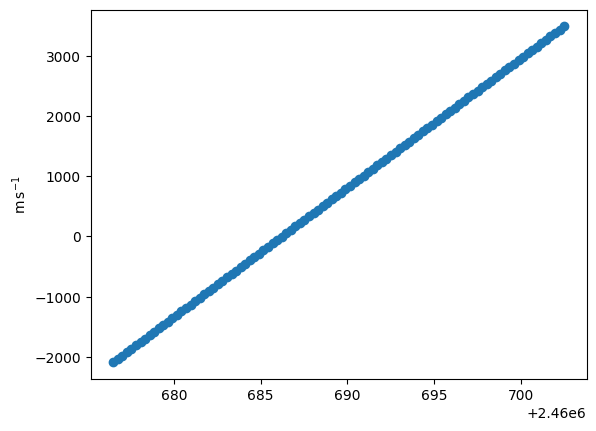

In [ ]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.axvline(peak_time.jd)

## Orbital period detection

In [ ]:
# import numpy
# peak_mag = numpy.max(lcg.timeseries['flux']) / numpy.median(lcg.timeseries['flux'])
# min_mag = peak_mag * 0.999
# max_mag = peak_mag * 1.001
# min_mag, peak_mag, max_mag

In [ ]:
# non_detection_times = [t for t in lcg.time_offsets if t not in lcg.peak_time_offsets]

In [ ]:
# from src.selflensing.porb import estimate_porb

# p = estimate_porb(sls.tau_eff, min_mag, max_mag, sls.Rcomp)
# p

In [ ]:
# from astropy import units
# bin_starts = units.Quantity(p[0])
# bin_ends = units.Quantity(p[1])
# bin_counts = numpy.array(p[2])
# total_count = sum(bin_counts)

# bin_widths = bin_ends - bin_starts
# bin_centres = (bin_starts + bin_ends) / 2
# n_density = (bin_counts/total_count) / bin_widths.to(units.year).value

# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [ ]:
# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.yscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [ ]:
# from src.selflensing.porb import LENS_MASS_DIST
# mass_bin_width = LENS_MASS_DIST[0, 1] - LENS_MASS_DIST[0, 0]
# pyplot.plot(LENS_MASS_DIST[0,:], LENS_MASS_DIST[1,:] / mass_bin_width)
# pyplot.axvline(sls.Macc.to(units.M_sun).value)

## Fitting

In [ ]:
sls_fit, sampler = self_lensing_system_from_fit(
    rv_times=rvg.times,
    observed_rv=rvg.rv,
    observed_rv_err=rvg.rv/10,
    lc_times=lcg.times,
    observed_lc=lcg.flux_array,
    observed_lc_err=1 * lcg.units,
    gp_model=TESSGP,
    peak_time=peak_time,
    Mcomp=sls.Mcomp,
    Rcomp=sls.Rcomp,
    Teff=sls.Teff,
    tau_eff=sls.tau_eff,
    d=sls.d,
    # period_min=350 * units.day,
    # detect_periods=True,
    nsteps=5000,
    # nwalkers=20,
    burn=10,
    lensing_method=LENSING_METHOD,
)


detected periods: []
db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float64[3888]>
db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float64[3888]>


  0%|          | 0/5000 [00:00<?, ?it/s]

In [ ]:
lcg_fit = LightcurveGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time, lensing_method=LENSING_METHOD, bins=27*24*6)
rvg_fit = RVGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time)

In [ ]:
lp = sampler.get_log_prob(flat=True)
min(lp), max(lp), lp

(np.float64(-inf),
 np.float64(-20116480303.485447),
 array([-9.06446717e+12, -8.68787831e+12, -8.05917446e+11, ...,
                   -inf,            -inf,            -inf], shape=(500000,)))

In [ ]:
sls_fit.a.value, sls_fit.i.value, sls_fit.Macc.value, sls_fit.e.value, sls_fit.periapsis_phase.value

(Array(168.75346297, dtype=float64),
 Array(1.57079628, dtype=float64),
 Array(49.9999995, dtype=float64),
 Array(0.99999897, dtype=float64),
 Array(3.141593, dtype=float64))

db r <class 'jax._src.interpreters.partial_eval.DynamicJaxprTracer'> JitTracer<float64[3888]>


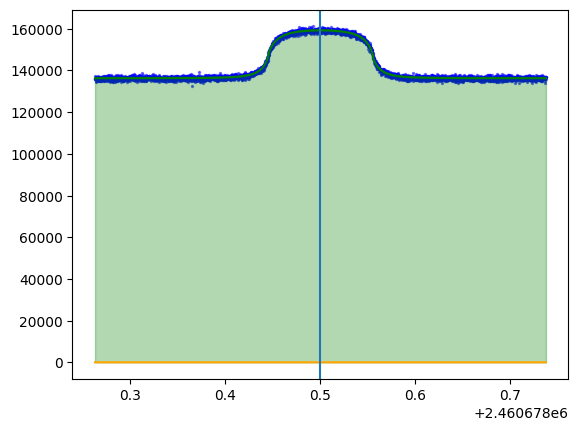

In [ ]:
scale = numpy.mean(lcg.gp.generate())
pyplot.scatter(lcg.times.jd, lcg.flux_array , s=2, alpha=0.5, c='blue') # Normalised observed light curve
# pyplot.plot(plain_lcg.times.jd, plain_lcg.flux_array, c='green') # Observed Lensing
pyplot.plot(lcg.times.jd, mu , c='green')
pyplot.fill_between(lcg.times.jd, (mu + std), (mu - std)/scale, color="green", alpha=0.3)
# pyplot.plot(model_lcg.times.jd, 1+(lcg.flux_array - model_lcg.gp.generate())/numpy.mean(model_lcg.gp.generate()), c='red')
pyplot.plot(lcg_fit.times.jd, lcg_fit.flux_array, c='orange') # Fitted lensing
pyplot.axvline(peak_time.jd)

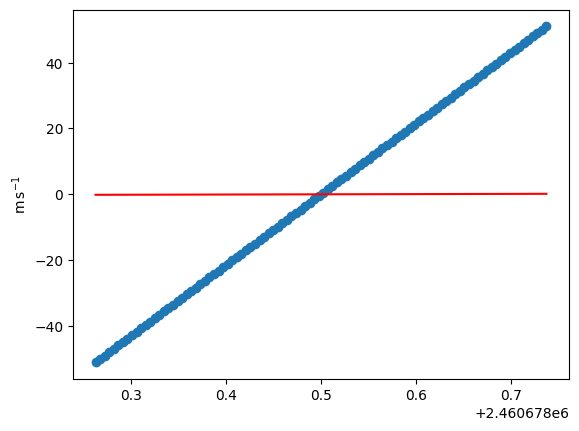

In [ ]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.plot(rvg_fit.times.jd, rvg_fit.rv, c='red')

Text(0.5, 0, 'step number')

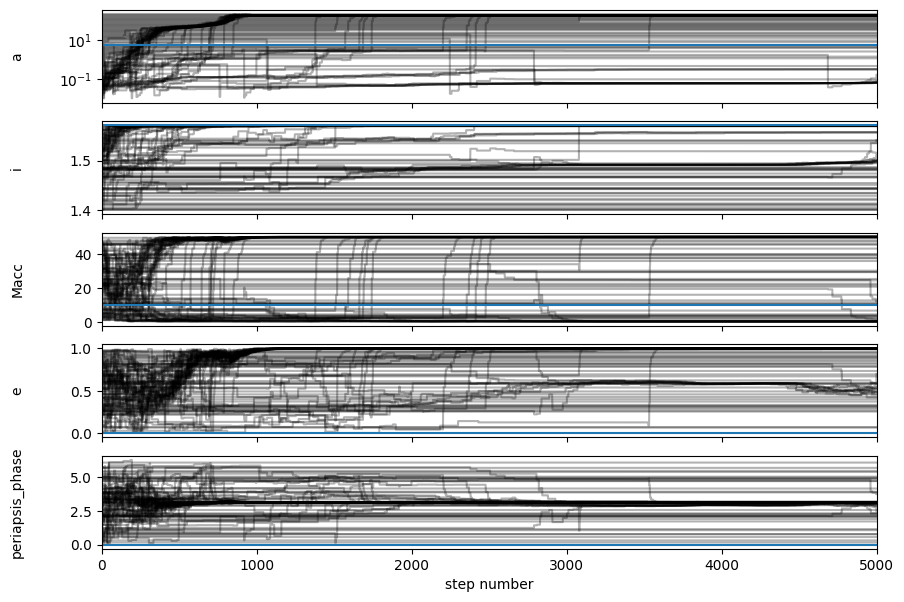

In [ ]:
truths=[sls.a.value, sls.i.value, sls.Macc.value, sls.e.value, sls.periapsis_phase.value]

from matplotlib import pyplot as plt
labels = ["a", "i", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.axhline(truths[i])
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)
axes[0].set_yscale('log')

axes[-1].set_xlabel("step number")

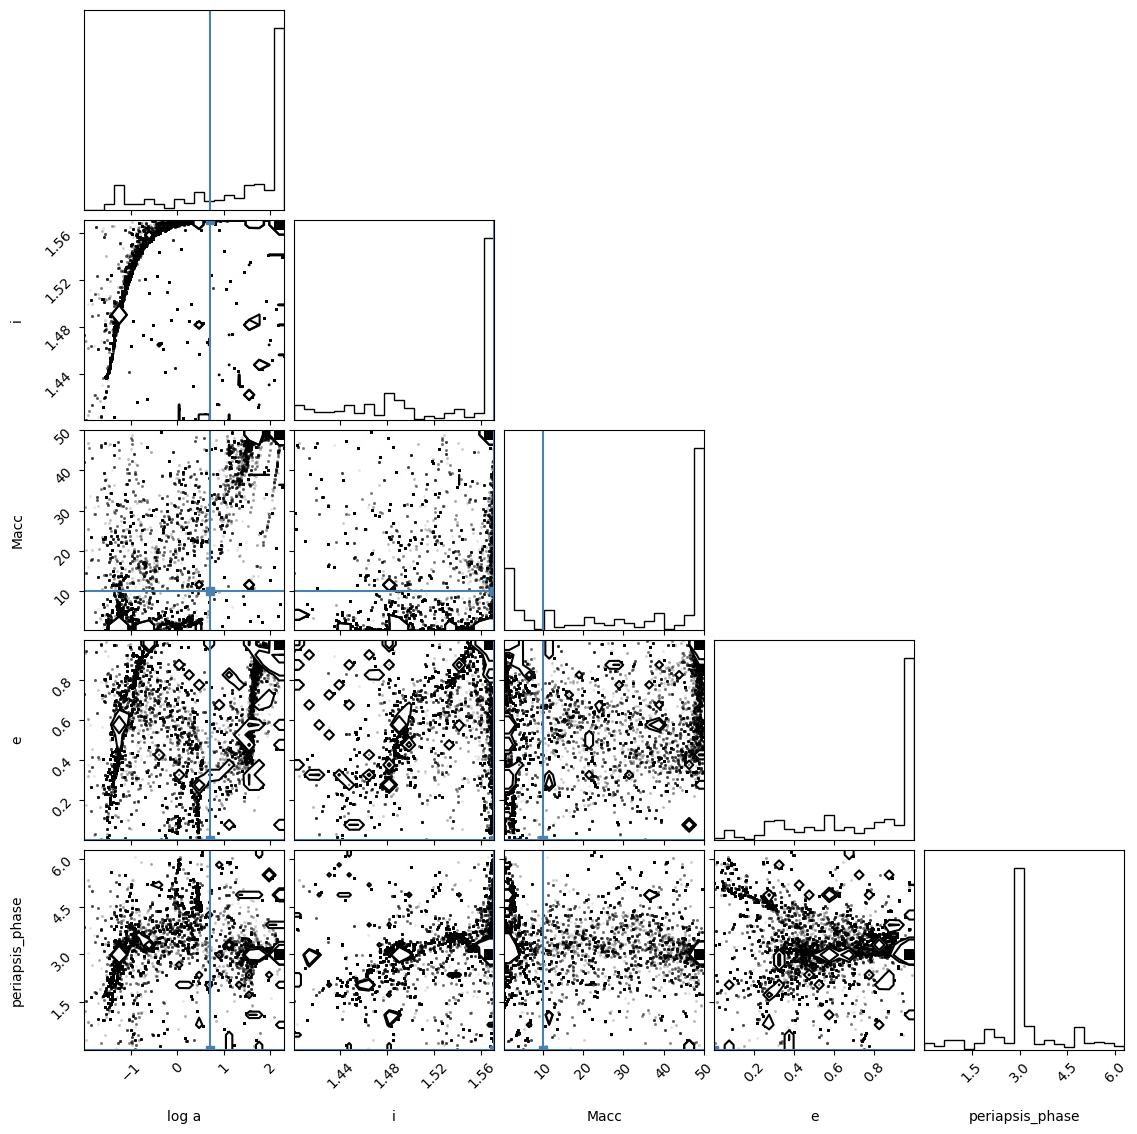

In [ ]:
import corner

flat_samples_log = flat_samples.copy()
flat_samples_log[:, 0] = numpy.log10(flat_samples[:, 0])
truths_log = truths.copy()
truths_log[0] = numpy.log10(truths[0])
labels_log = labels.copy()
labels_log[0] = 'log ' + labels[0]
fig = corner.corner(
    flat_samples_log, labels=labels_log, truths=truths_log
)